# SAMPLER demo — run me top to bottom

This notebook loads the slide representations, loads the trained model, and paints
two tumor **attention maps** inline. Use **Run All** (the ⏩ button at the top), or
run each cell with **Shift+Enter**.

If VS Code asks for a *kernel*, pick the Python at
`/opt/homebrew/Caskroom/miniforge/base/bin/python3`.

## 1. Imports and settings

In [1]:
import os, pickle
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import SAMPLER  # the helper library in this folder

DATA = "data"                                  # where the big .p files live
fdim = 2048                                    # features per tile, per magnification
pers = [5,15,25,35,45,55,65,75,85,95]          # the 10 percentiles SAMPLER uses
dsr = 4                                         # map downsample factor

def load(name):
    with open(os.path.join(DATA, name), "rb") as f:
        return pickle.load(f)

print("ready")

ready


## 2. Load the slide representations
Each row is one whole slide, summarized as 61,440 numbers (2048 features × 10 percentiles × 3 magnifications).

In [2]:
D = load("TCGA_BRCA_DX20X.p")
Xtrain, Ytrain = D["Xtrain"], D["Ytrain"]
print("Xtrain shape:", Xtrain.shape, "  (slides x features)")
print("class counts (normal, tumor):", np.bincount(Ytrain.astype(int)))

Xtrain shape: (693, 61440)   (slides x features)
class counts (normal, tumor): [551 142]


## 3. Feature weights (t-test) + load the trained model

In [3]:
# t-test between the two classes -> weight = -log(p-value)
_, P = sp.stats.ttest_ind(Xtrain[Ytrain==0,:], Xtrain[Ytrain==1,:])
rate = len(pers)
Pmat = np.zeros((rate, 3*fdim))
for i in range(rate):
    Pmat[i, :fdim]           = P[i*fdim:(i+1)*fdim]
    Pmat[i, fdim:2*fdim]     = P[fdim+i*fdim:fdim+(i+1)*fdim]
    Pmat[i, 2*fdim:3*fdim]   = P[2*fdim+i*fdim:2*fdim+(i+1)*fdim]
Wmat = -np.log(Pmat)

Dtab = load("Dtab.p")   # trained likelihood-ratio lookup tables
print("model loaded. LLR table shape:", Dtab["LLR_R_C_0"].shape, "(features x percentiles x grid)")

model loaded. LLR table shape: (2048, 10, 20) (features x percentiles x grid)


## 4. A helper that scores one slide and builds its map

In [4]:
def attention_map(slide, cls, use_abs=False):
    W = load(slide + ".p")
    feats = W["feats"][::3, :]        # subsample tiles x3 for speed
    locs  = (W["locs"][::3, :] / dsr).astype(np.int32)
    XR, XP, XB = feats[:, :fdim], feats[:, fdim:2*fdim], feats[:, 2*fdim:]
    sR = SAMPLER.Sscore(XR, Dtab["XtabR"], Dtab[f"LLR_R_C_{cls}"], Wmat[:, :fdim], pers)
    sP = SAMPLER.Sscore(XP, Dtab["XtabP"], Dtab[f"LLR_P_C_{cls}"], Wmat[:, fdim:2*fdim], pers)
    sB = SAMPLER.Sscore(XB, Dtab["XtabB"], Dtab[f"LLR_B_C_{cls}"], Wmat[:, 2*fdim:], pers)
    scores = np.sum(sR,1) + np.sum(sP,1) + np.sum(sB,1)
    if use_abs: scores = np.abs(scores)
    scores = SAMPLER.normalize_scores(scores)
    return SAMPLER.hmapgen3(scores, locs, int(512/dsr))

## 5. Slide 1 — paint the map (red = tumor-like, blue = not, white = no tissue)

map shape: (10368, 9152, 3)


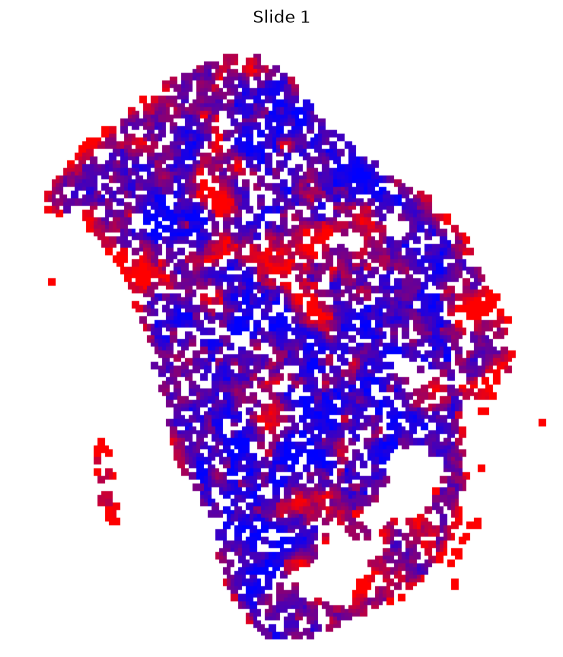

In [5]:
hmap1 = attention_map("TCGA-AR-A0TP-01Z-00-DX1.58E6A3A6-D1D7-4AE5-87A5-E823F04CBB2F.svs", cls=0)
print("map shape:", hmap1.shape)
plt.figure(figsize=(8,8)); plt.imshow(hmap1); plt.axis("off"); plt.title("Slide 1"); plt.show()

## 6. Slide 2

map shape: (7616, 14528, 3)


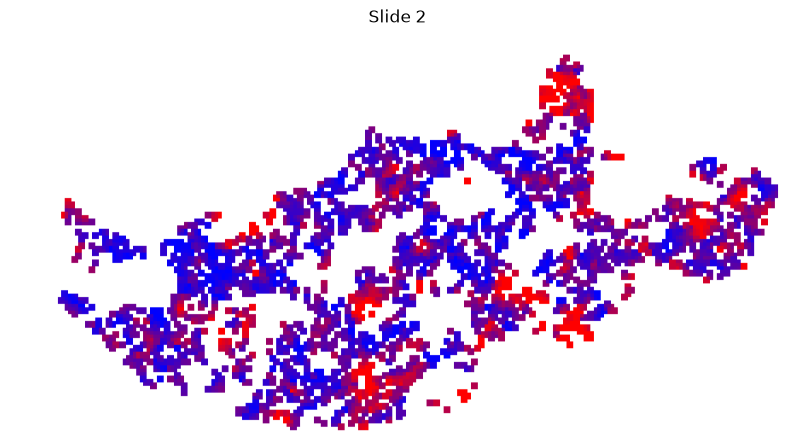

In [6]:
hmap2 = attention_map("TCGA-B6-A0RQ-01Z-00-DX1.68B4F49D-9F81-4501-BC66-0349012077C8.svs", cls=1, use_abs=True)
print("map shape:", hmap2.shape)
plt.figure(figsize=(10,6)); plt.imshow(hmap2); plt.axis("off"); plt.title("Slide 2"); plt.show()